# Exploratory Data Analysis: NYC restaurant inspections

This notebook explores the processed NYC restaurant inspection dataset and examines patterns related to the main target variable, `fail`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../data/processed/inspections_model.csv")
df.shape

(44890, 24)

In [3]:
df.head()

,camis,dba,inspection_date,boro,zipcode,cuisine_description,latitude,longitude,is_chain,inspection_year,...,prev_initial_score,prev_initial_failed,mean_prior_initial_score,max_prior_initial_score,n_prior_critical_violations,n_prior_closures,days_since_prev_inspection,days_since_prev_initial,score,fail
0,41219793,THE MONKEY ROOM,2023-01-03,Manhattan,10033.0,American,40.854623,-73.937051,0,2023,...,NaN,NaN,NaN,NaN,0,0,NaN,NaN,9.0,0
1,41462617,MIKE'S UNICORN DINER,2023-01-03,Staten Island,10314.0,American,40.607389,-74.160675,0,2023,...,NaN,NaN,NaN,NaN,0,0,NaN,NaN,19.0,1
2,41615012,VERONICA'S BAKERY,2023-01-03,Staten Island,10302.0,Mexican,40.631062,-74.130952,0,2023,...,NaN,NaN,NaN,NaN,0,0,NaN,NaN,31.0,1
3,41630104,LUCKY CHINESE RESTAURANT,2023-01-03,Queens,11377.0,Chinese,40.736744,-73.895975,0,2023,...,31.0,1.0,31.0,31.0,6,0,224.0,250.0,41.0,1
4,50003774,GOLDEN KRUST CARIBBEAN BAKERY & GRILL,2023-01-03,Brooklyn,11210.0,Caribbean,40.636919,-73.937311,1,2023,...,NaN,NaN,NaN,NaN,0,0,NaN,NaN,14.0,1


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 44890 entries, 0 to 44889
Data columns (total 24 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   camis                        44890 non-null  int64  
 1   dba                          44890 non-null  str    
 2   inspection_date              44890 non-null  str    
 3   boro                         44848 non-null  str    
 4   zipcode                      44295 non-null  float64
 5   cuisine_description          44890 non-null  str    
 6   latitude                     44016 non-null  float64
 7   longitude                    44016 non-null  float64
 8   is_chain                     44890 non-null  int64  
 9   inspection_year              44890 non-null  int64  
 10  inspection_month             44890 non-null  int64  
 11  inspection_dayofweek         44890 non-null  int64  
 12  n_prior_inspections          44890 non-null  int64  
 13  n_prior_initial_inspections

## Target Distribution

In [5]:
df["fail"].value_counts()

fail
0    26906
1    17984
Name: count, dtype: int64

In [6]:
df["fail"].value_counts(normalize=True)

fail
0    0.599376
1    0.400624
Name: proportion, dtype: float64

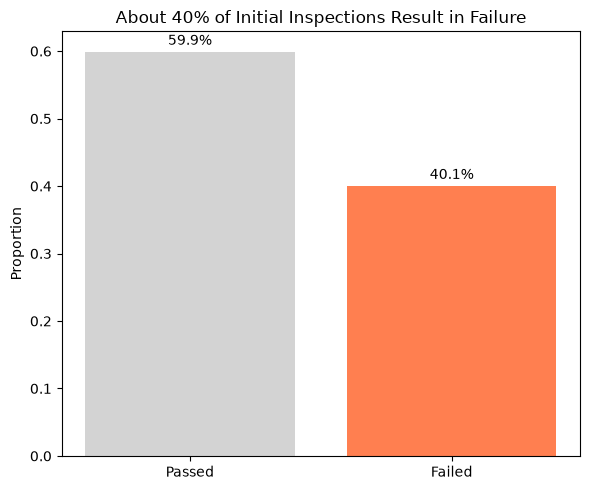

In [32]:
fail_rate = df["fail"].mean()
rates = [1 - fail_rate, fail_rate]

plt.figure(figsize=(6, 5))

bars = plt.bar(
    ["Passed", "Failed"],
    rates,
    color=["lightgray", "coral"]
)

for bar, rate in zip(bars, rates):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f"{rate:.1%}",
        ha="center"
    )

plt.ylabel("Proportion")
plt.title("About 40% of Initial Inspections Result in Failure")

plt.tight_layout()
plt.show()

**Observation:** About 40.1% of the initial inspections in the dataset are classified as failures, while 59.9% are passes. The target is therefore not extremely imbalanced.

## Missing Values

In [8]:
df.isna().sum()

camis                              0
dba                                0
inspection_date                    0
boro                              42
zipcode                          595
cuisine_description                0
latitude                         874
longitude                        874
is_chain                           0
inspection_year                    0
inspection_month                   0
inspection_dayofweek               0
n_prior_inspections                0
n_prior_initial_inspections        0
prev_initial_score             20763
prev_initial_failed            20763
mean_prior_initial_score       20763
max_prior_initial_score        20763
n_prior_critical_violations        0
n_prior_closures                   0
days_since_prev_inspection     12376
days_since_prev_initial        20763
score                              0
fail                               0
dtype: int64

In [9]:
df.isna().mean()

camis                          0.000000
dba                            0.000000
inspection_date                0.000000
boro                           0.000936
zipcode                        0.013255
cuisine_description            0.000000
latitude                       0.019470
longitude                      0.019470
is_chain                       0.000000
inspection_year                0.000000
inspection_month               0.000000
inspection_dayofweek           0.000000
n_prior_inspections            0.000000
n_prior_initial_inspections    0.000000
prev_initial_score             0.462531
prev_initial_failed            0.462531
mean_prior_initial_score       0.462531
max_prior_initial_score        0.462531
n_prior_critical_violations    0.000000
n_prior_closures               0.000000
days_since_prev_inspection     0.275696
days_since_prev_initial        0.462531
score                          0.000000
fail                           0.000000
dtype: float64

In [10]:
df.loc[
    df["prev_initial_score"].isna(),
    "n_prior_initial_inspections"
].value_counts()

n_prior_initial_inspections
0    20763
Name: count, dtype: int64

**Missing Value Interpretation:** All 20,763 observations with a missing `prev_initial_score` have zero prior initial inspections. Therefore, these missing values are expected: if a restaurant has no prior initial inspection in the available data, there is no previous inspection score to record.

## Feature Exploration

### Borough

In [11]:
boro_fail_rate = df.groupby("boro")["fail"].mean().sort_values()
boro_fail_rate

boro
Manhattan        0.380622
Brooklyn         0.386890
Bronx            0.419518
Queens           0.433469
Staten Island    0.455112
Name: fail, dtype: float64

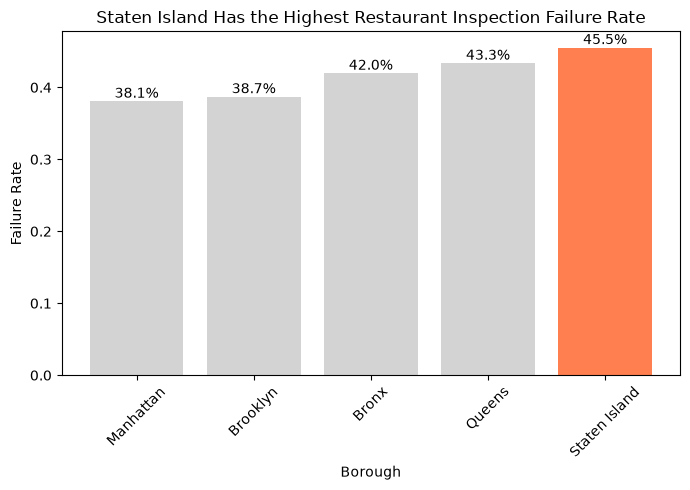

In [33]:
colors = [
    "lightgray" if boro != "Staten Island" else "coral"
    for boro in boro_fail_rate.index
]

plt.figure(figsize=(7, 5))

bars = plt.bar(
    boro_fail_rate.index,
    boro_fail_rate.values,
    color=colors
)

for bar, rate in zip(bars, boro_fail_rate.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.005,
        f"{rate:.1%}",
        ha="center"
    )

plt.xlabel("Borough")
plt.ylabel("Failure Rate")
plt.title("Staten Island Has the Highest Restaurant Inspection Failure Rate")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Observation:** Staten Island has the highest inspection failure rate at 45.5%, while Manhattan has the lowest at 38.1%. However, the differences across boroughs are relatively modest.

### Cuisine

In [13]:
df["cuisine_description"].nunique()

89

In [14]:
df["cuisine_description"].value_counts().head(15)

cuisine_description
American                          7861
Coffee/Tea                        4041
Chinese                           3464
Pizza                             2748
Bakery Products/Desserts          1927
Latin American                    1917
Mexican                           1711
Donuts                            1519
Italian                           1510
Caribbean                         1357
Japanese                          1353
Chicken                           1277
Hamburgers                        1121
Sandwiches                         963
Juice, Smoothies, Fruit Salads     892
Name: count, dtype: int64

In [15]:
cuisine_summary = (
    df.groupby("cuisine_description")["fail"]
    .agg(["count", "mean"])
)

cuisine_summary = cuisine_summary[
    cuisine_summary["count"] >= 300
]

In [16]:
cuisine_plot = pd.concat([
    cuisine_summary.nsmallest(5, "mean"),
    cuisine_summary.nlargest(5, "mean")
]).sort_values("mean")

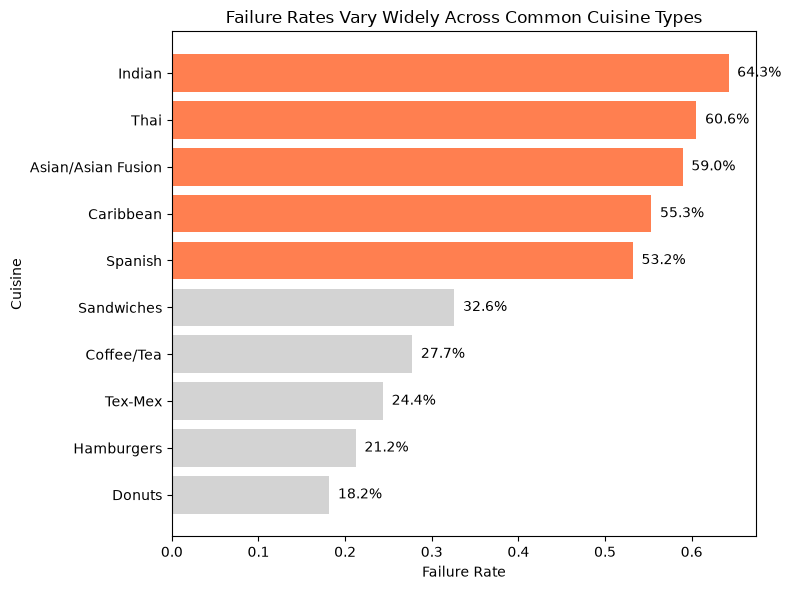

In [34]:
colors = [
    "coral" if rate >= 0.5 else "lightgray"
    for rate in cuisine_plot["mean"]
]

plt.figure(figsize=(8, 6))

bars = plt.barh(
    cuisine_plot.index,
    cuisine_plot["mean"],
    color=colors
)

for bar, rate in zip(bars, cuisine_plot["mean"]):
    plt.text(
        bar.get_width() + 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{rate:.1%}",
        va="center"
    )

plt.xlabel("Failure Rate")
plt.ylabel("Cuisine")
plt.title("Failure Rates Vary Widely Across Common Cuisine Types")

plt.tight_layout()
plt.show()

**Observation:** Among cuisine categories with at least 300 inspections, failure rates vary substantially. The figure shows the five cuisines with the highest and lowest failure rates. Some of the highest-risk cuisines have failure rates above 50%, while the lowest are below 25%. This indicates an association between cuisine category and inspection outcomes, but does not imply causation.

### Inspection History

In [24]:
df["prev_initial_score"].describe()

count    24127.000000
mean        17.432006
std         13.913361
min          0.000000
25%          9.000000
50%         12.000000
75%         23.000000
max        142.000000
Name: prev_initial_score, dtype: float64

In [25]:
prev_score_fail_rate = (
    df.groupby("prev_initial_score")["fail"]
    .agg(["count", "mean"])
)

prev_score_fail_rate

,count,mean
prev_initial_score,,
0.0,234,0.303419
2.0,893,0.208287
3.0,355,0.169014
4.0,492,0.182927
5.0,936,0.230769
...,...,...
121.0,1,1.000000
127.0,1,1.000000
128.0,1,1.000000


In [26]:
score_bins = [-1, 5, 13, 20, 30, np.inf]
score_labels = ["0-5", "6-13", "14-20", "21-30", "31+"]

df["prev_score_group"] = pd.cut(
    df["prev_initial_score"],
    bins=score_bins,
    labels=score_labels
)

In [27]:
score_group_summary = (
    df.groupby("prev_score_group", observed=True)["fail"]
    .agg(["count", "mean"])
)

score_group_summary

,count,mean
prev_score_group,,
0-5,2910,0.214089
6-13,11853,0.312242
14-20,2083,0.447432
21-30,3840,0.515365
31+,3441,0.586167


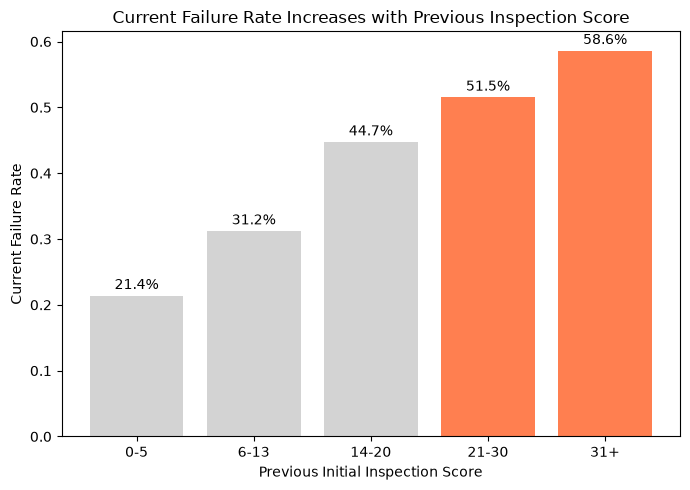

In [35]:
colors = [
    "coral" if rate >= 0.5 else "lightgray"
    for rate in score_group_summary["mean"]
]

plt.figure(figsize=(7, 5))

bars = plt.bar(
    score_group_summary.index,
    score_group_summary["mean"],
    color=colors
)

for bar, rate in zip(bars, score_group_summary["mean"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f"{rate:.1%}",
        ha="center"
    )

plt.xlabel("Previous Initial Inspection Score")
plt.ylabel("Current Failure Rate")
plt.title("Current Failure Rate Increases with Previous Inspection Score")

plt.tight_layout()
plt.show()

**Observation:** Restaurants with higher previous initial inspection scores tend to have higher failure rates in their current inspection. The failure rate increases from 21.4% for restaurants with previous scores of 0–5 to 58.6% for those with previous scores of 31 or higher.

### Chain Status

In [30]:
df.groupby("is_chain")["fail"].agg(["count", "mean"])

,count,mean
is_chain,,
0,35712,0.43624
1,9178,0.26204


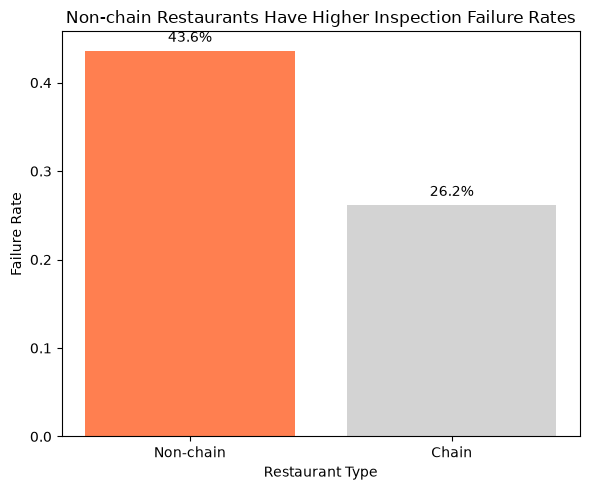

In [36]:
chain_fail_rate = df.groupby("is_chain")["fail"].mean()

plt.figure(figsize=(6, 5))

bars = plt.bar(
    ["Non-chain", "Chain"],
    chain_fail_rate.values,
    color=["coral", "lightgray"]
)

for bar, rate in zip(bars, chain_fail_rate.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f"{rate:.1%}",
        ha="center"
    )

plt.xlabel("Restaurant Type")
plt.ylabel("Failure Rate")
plt.title("Non-chain Restaurants Have Higher Inspection Failure Rates")

plt.tight_layout()
plt.show()

**Observation:** Non-chain restaurants have a substantially higher inspection failure rate than chain restaurants. The failure rate is 43.6% for non-chain restaurants, compared with 26.2% for chain restaurants. This suggests an association between chain status and inspection outcomes.